In [1]:
import numpy as np
from torch.utils.data import Dataset
import torchvision.transforms.v2 as T
from torchvision.datasets import MNIST
import matplotlib.pyplot as plt
from pathlib import Path

from accuracy_bounds.classificationproblems.utils import wavelet_array_features
from accuracy_bounds.classificationproblems.feasible_sets import feasible_sets_classification_nn
from accuracy_bounds.classificationproblems.kersize_compute import compute_kernel_size_one_hot

---
## Load the data

In [2]:
data_root = Path("data/raw/")
data_path = data_root / "MNIST"

seed = 42
img_size = 28

train_subset_size = None

In [3]:
def build_split_data(data_path: Path, train_subset_size=None, seed=42):
    """Download MNIST and return uint8 images (N, 28, 28) and int labels per split.

    MNIST only has an official train/test split, so "val" is left empty.
    """
    data_path.mkdir(parents=True, exist_ok=True)
    train_raw = MNIST(data_path, train=True, download=True)
    test_raw = MNIST(data_path, train=False, download=True)

    train_x, train_y = train_raw.data, train_raw.targets
    if train_subset_size is not None:
        rng = np.random.default_rng(seed)
        idx = np.sort(rng.choice(len(train_x), train_subset_size, replace=False))
        train_x, train_y = train_x[idx], train_y[idx]

    split_data = {
        "classes": [str(i) for i in range(10)],
        "train": (train_x, train_y.tolist()),
        "val": (train_x[:0], []),
        "test": (test_raw.data, test_raw.targets.tolist()),
    }
    for subset in ("train", "val", "test"):
        print(f"{subset}: {len(split_data[subset][1])} samples")
    return split_data


class MNISTDataset(Dataset):
    def __init__(self, split_data, subset, transform=None):
        assert subset in ("train", "val", "test")
        self.images, labels = split_data[subset]
        self.classes = split_data["classes"]
        self.transform = transform
        self.subset = subset
        self._clean_labels = list(labels)
        self.targets = list(labels)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        # (1, 28, 28) float32 tensor with values in [0, 1]
        img = self.images[idx].unsqueeze(0).float() / 255.0

        if self.transform:
            img = self.transform(img)
        return img, self.targets[idx]


def to_arrays(dataset):
    """Stack a dataset into (N, 1, 28, 28) images and (N,) labels."""
    images = np.stack([img.numpy() for img, _ in dataset])
    labels = np.array(dataset.targets)
    return images, labels

In [4]:
# number of subprocesses to use for data loading
num_workers = 0
# how many samples per batch to load
batch_size = 32

train_tf = eval_tf = T.Normalize(mean=[0.5], std=[0.5])

split_data = build_split_data(data_path, train_subset_size=train_subset_size, seed=seed)

train_data = MNISTDataset(split_data, "train", transform=train_tf)
val_data   = MNISTDataset(split_data, "val",   transform=eval_tf)
test_data  = MNISTDataset(split_data, "test",  transform=eval_tf)

# specify the image classes
classes = split_data["classes"]

100%|██████████| 9.91M/9.91M [00:01<00:00, 7.24MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.13MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.81MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.57MB/s]

train: 60000 samples
val: 0 samples
test: 10000 samples


## Average kernel size for one Mickey Mouse image to labels of MNIST

In [5]:
from collections import Counter

counts = Counter(test_data.targets)

M = len(test_data.targets)

same_pairs = sum(n * (n - 1) // 2 for n in counts.values())
total_pairs = M * (M - 1) // 2
diff_pairs = total_pairs - same_pairs

average_kersize = 2 * diff_pairs / total_pairs / 2

print(M)
print(counts)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)

10000
Counter({1: 1135, 2: 1032, 7: 1028, 3: 1010, 9: 1009, 4: 982, 0: 980, 8: 974, 6: 958, 5: 892})
Upper accuracy bound: 0.5501302230223022


## Average kernel size on training set

In [6]:
train_images, train_labels = to_arrays(train_data)

print(train_images.shape)   # (60000, 1, 28, 28)
print(train_labels.shape)   # (60000,)

(60000, 1, 28, 28)
(60000,)


### Get wavelet features on training set

In [7]:
train_features = wavelet_array_features(train_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [8]:
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(train_features, train_labels, N_max=200, qx=0.1)
tau_x = feas["tau_x"]
feasible_sets = feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
print("average_kersize on test set: ", average_kersize)
print("Lower accuracy bound:", 1 - average_kersize)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)
print("D':", D_prime)
print("tau_x:", tau_x)
print("M':", M_prime)
print("Nk:", Nk_stats)

average_kersize on test set:  0.0
Lower accuracy bound: 1.0
Upper accuracy bound: 1.0
D': []
tau_x: 4.732302331924439
M': 267780
Nk: (1, 4.463, 1.0, 186)


### Ablation on maximum number of nearest neighbors and quantiles

In [9]:
train_result_dict = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None  # go through N_max in reverse order to only compute the largest N once

for N_id, N_max in enumerate(N_list):
    train_result_dict[N_max] = {}

    for qx_id, qx in enumerate(qx_list):
        train_result_dict[N_max][qx] = {"avg_ker_size": None,
                                  "tau_x": None,
                                  "N_k_stats": None}

        print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
        feas = feasible_sets_classification_nn(train_features, train_labels,
                                               N_max=N_max,
                                               qx=qx,
                                               neighbor_stats=neighbor_stats)

        tau_x = feas["tau_x"]
        feasible_sets = feas["feasible_sets"]
        D_prime = feas["D_prime"]

        if neighbor_stats is None:
            neighbor_stats = {"distances": feas["distances"],
                              "indices": feas["indices"]}

        average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
        train_result_dict[N_max][qx]["avg_ker_size"] = average_kersize
        train_result_dict[N_max][qx]["tau_x"] = tau_x
        train_result_dict[N_max][qx]["N_k_stats"] = Nk_stats

## Average kernel size on test set

In [10]:
test_images, test_labels = to_arrays(test_data)

print(test_images.shape)   # (10000, 1, 28, 28)
print(test_labels.shape)   # (10000,)

(10000, 1, 28, 28)
(10000,)


### Get wavelet features on test set

In [11]:
test_features = wavelet_array_features(test_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [12]:
feas = feasible_sets_classification_nn(test_features, test_labels, N_max=200, qx=0.1)
tau_x = feas["tau_x"]
feasible_sets = feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
print("average_kersize on test set: ", average_kersize)
print("Lower accuracy bound:", 1 - average_kersize)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)
print("D':", D_prime)
print("tau_x:", tau_x)
print("M':", M_prime)
print("Nk:", Nk_stats)

average_kersize on test set:  0.0
Lower accuracy bound: 1.0
Upper accuracy bound: 1.0
D': []
tau_x: 5.381924390792848
M': 25100
Nk: (1, 2.51, 1.0, 71)


### Best accuracy on constructed test dataset

In [13]:
def compute_accuracy_star(feasible_sets):
    """Compute Acc_* for a collection of feasible sets."""
    return sum(
        max(np.bincount(Y.astype(int)))
        for Y in feasible_sets if len(Y)
    ) / sum(len(Y) for Y in feasible_sets)


Acc = compute_accuracy_star(feasible_sets)
print("Best accuracy on constructed test dataset", Acc)

Best accuracy on constructed test dataset 1.0


### Ablation on quantiles and maximum number of nearest neighbors

In [14]:
test_result_dict = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None  # go through N_max in reverse order to only compute the largest N once

for N_id, N_max in enumerate(N_list):
    test_result_dict[N_max] = {}

    for qx_id, qx in enumerate(qx_list):
        test_result_dict[N_max][qx] = {"avg_ker_size": None,
                                  "tau_x": None,
                                  "N_k_stats": None}

        print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
        feas = feasible_sets_classification_nn(test_features, test_labels,
                                               N_max=N_max,
                                               qx=qx,
                                               neighbor_stats=neighbor_stats)

        tau_x = feas["tau_x"]
        feasible_sets = feas["feasible_sets"]
        D_prime = feas["D_prime"]

        if neighbor_stats is None:
            neighbor_stats = {"distances": feas["distances"],
                              "indices": feas["indices"]}

        average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
        test_result_dict[N_max][qx]["avg_ker_size"] = average_kersize
        test_result_dict[N_max][qx]["tau_x"] = tau_x
        test_result_dict[N_max][qx]["N_k_stats"] = Nk_stats

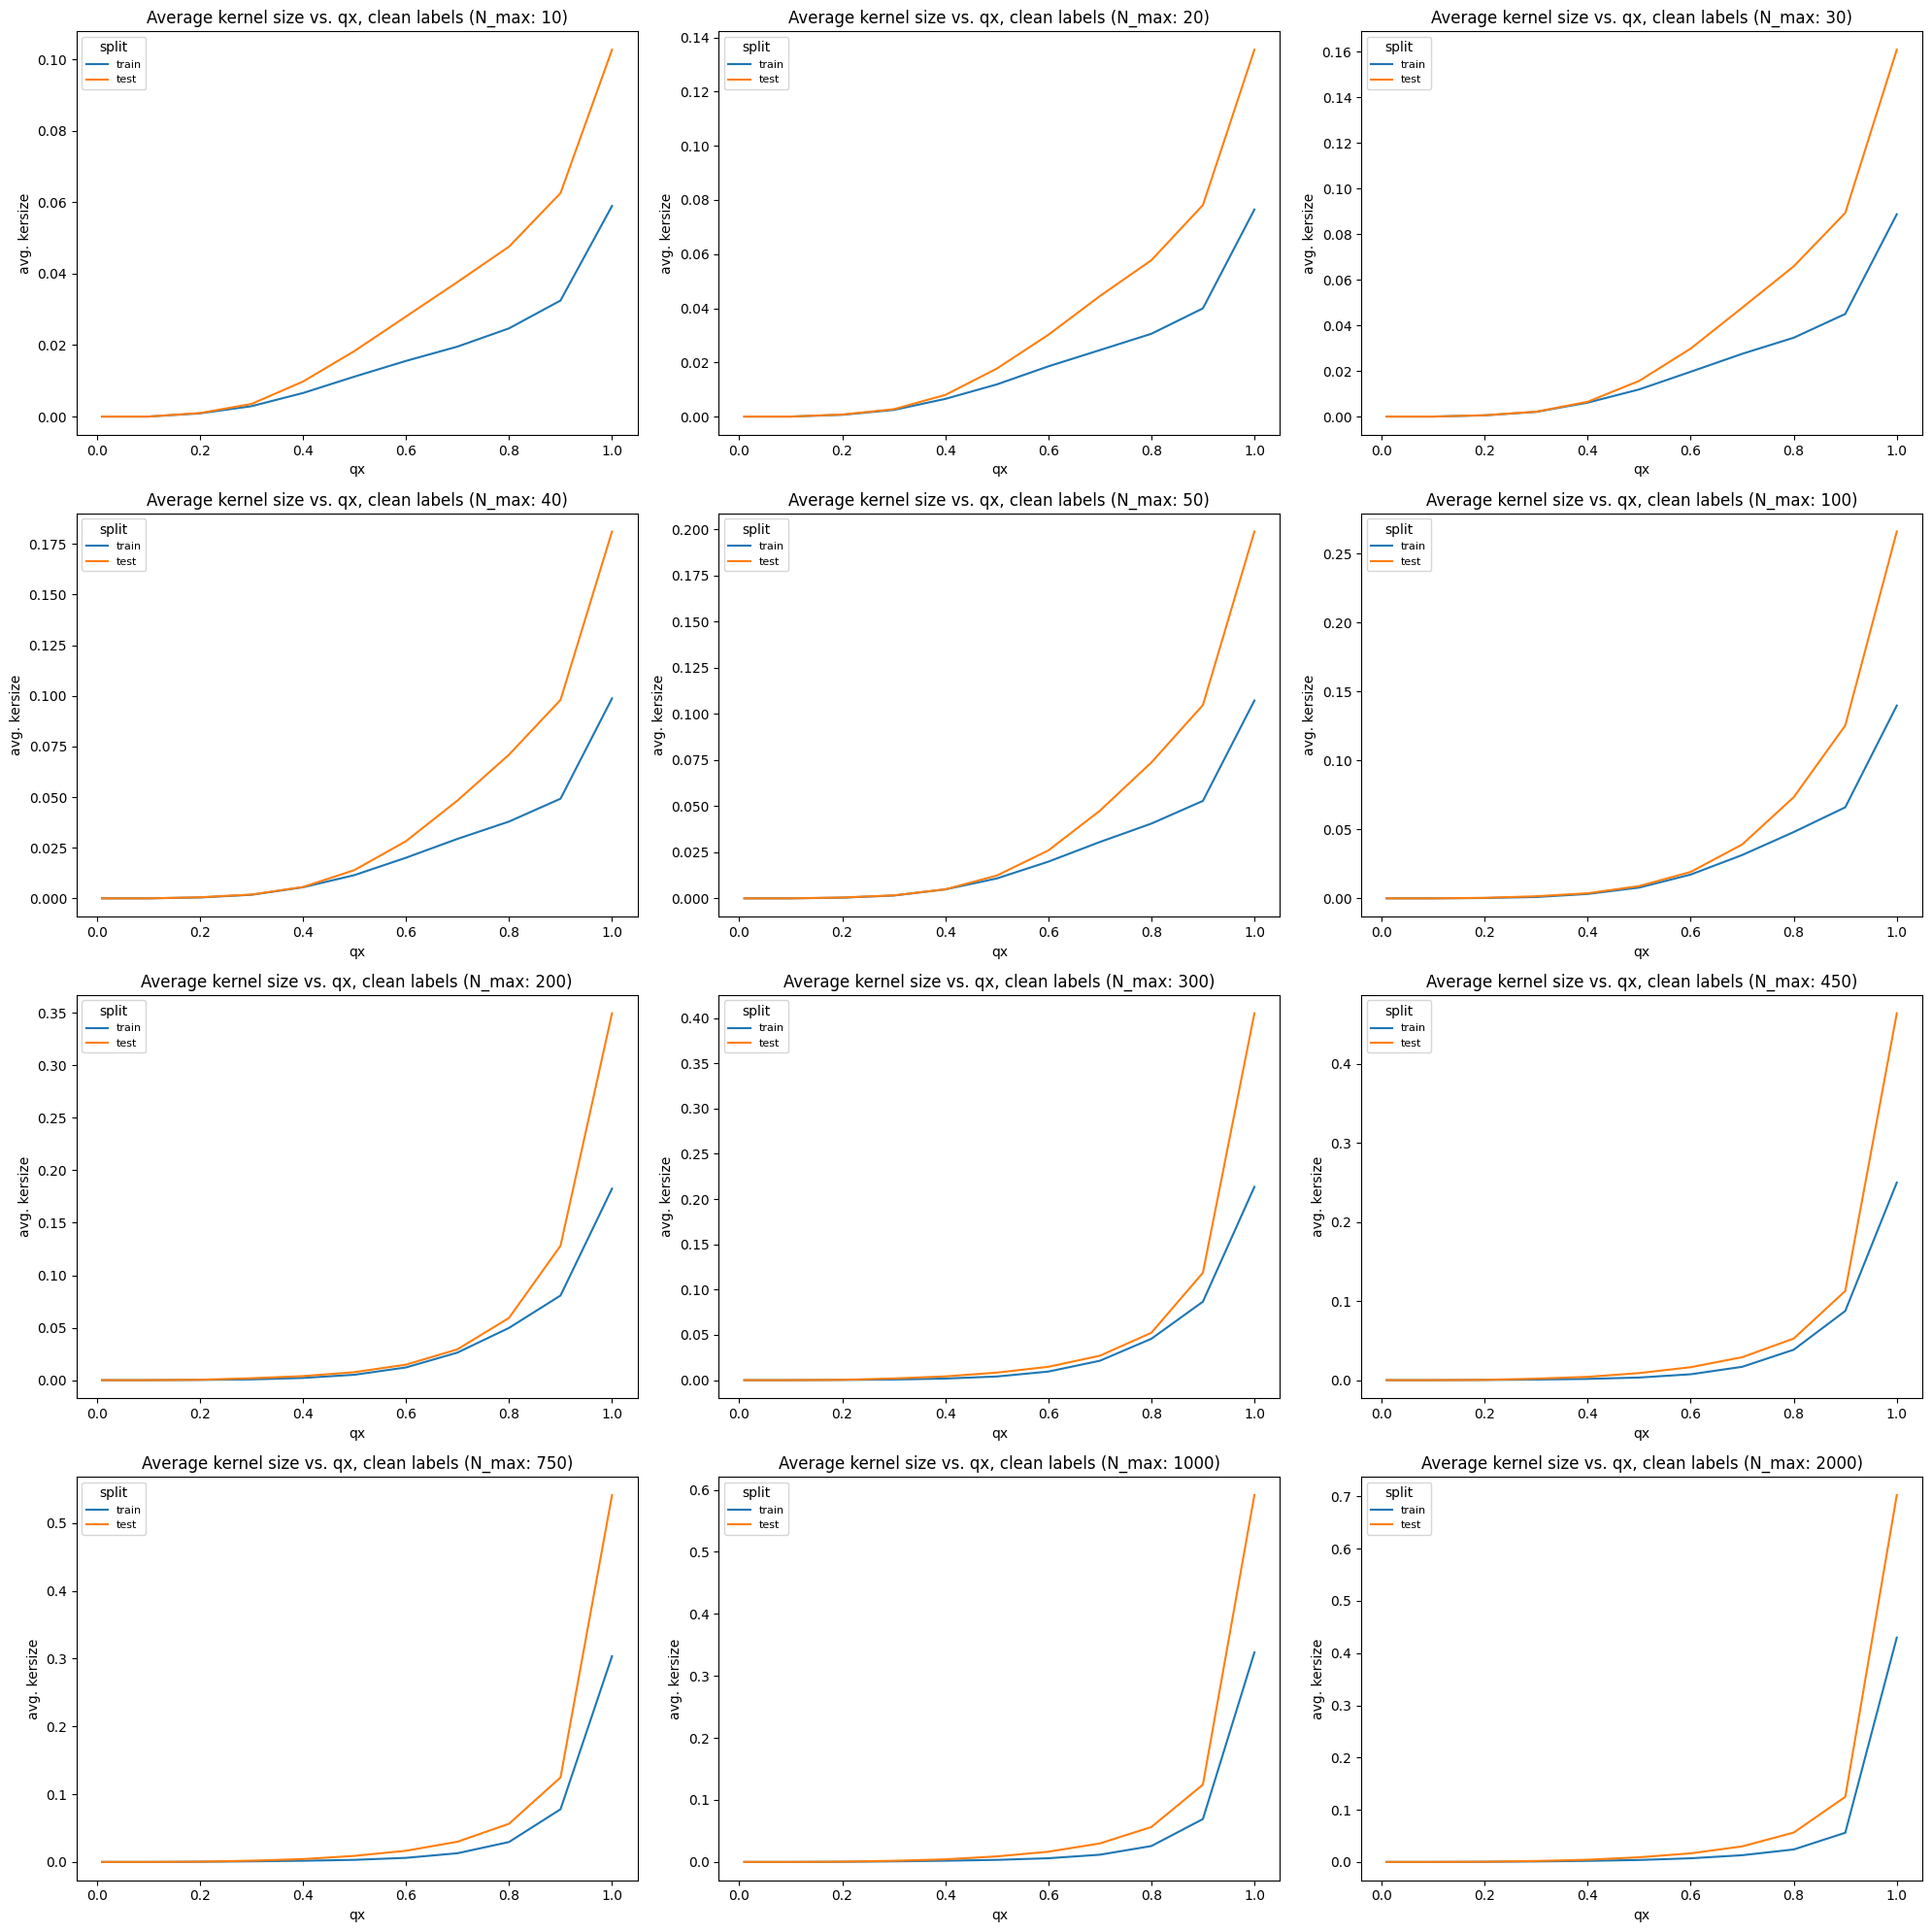

In [15]:
# train_result_dict / test_result_dict[N_max][qx]["avg_ker_size"]
n_max_list = sorted(train_result_dict)
qx_values = list(train_result_dict[n_max_list[0]])

num_cols = 3
fig, ax = plt.subplots(int(np.ceil(len(n_max_list) / num_cols)), num_cols,
                       figsize=(20, 5 * int(np.ceil(len(n_max_list) / num_cols))), squeeze=False)
for a, n in zip(ax.flat, n_max_list):
    for name, d in [("train", train_result_dict), ("test", test_result_dict)]:
        a.plot(qx_values, [d[n][qx]["avg_ker_size"] for qx in qx_values], label=name)
    a.set_title(f"Average kernel size vs. qx, clean labels (N_max: {n})")
    a.set_xlabel("qx")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8, title="split")
for a in ax.flat[len(n_max_list):]:
    a.axis("off")
plt.tight_layout()
plt.show()

## Visualize Feasible Sets

In [16]:
# generate feasible sets on test set for visualization
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(test_features, test_labels, test_images, N_max=200, qx=0.1, ext_d=True)
tau_x = feas["tau_x"]
feasible_sets = feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

tau_x: 5.381924390792848


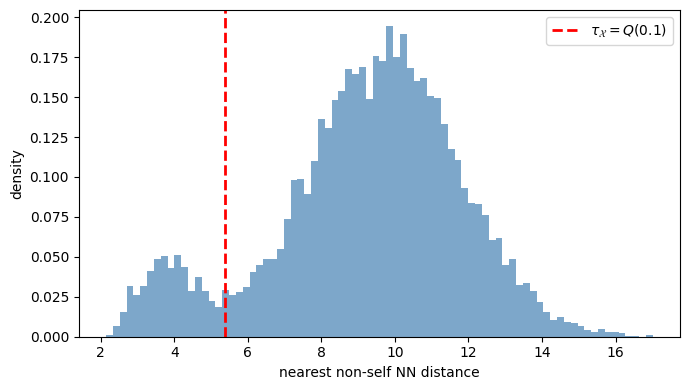

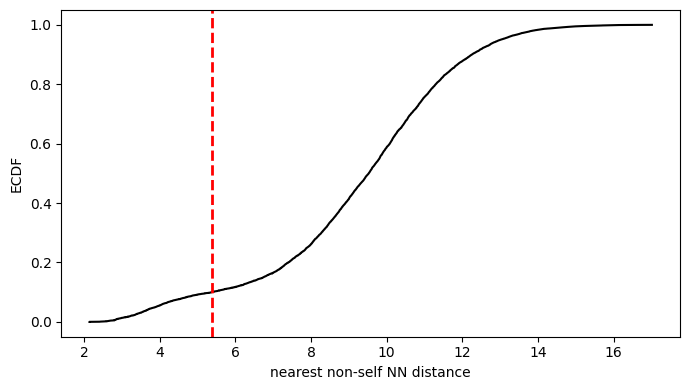

In [17]:
nearest_dist = distances[:, 1]  # nearest non-self distance
tau_x = np.quantile(nearest_dist, 0.1)

print("tau_x:", tau_x)

# --- histogram ---
plt.figure(figsize=(7, 4))
plt.hist(nearest_dist, bins=80, density=True, alpha=0.7, color="steelblue")
plt.axvline(tau_x, color="red", linestyle="--", linewidth=2,
            label=fr"$\tau_\mathcal{{X}} = Q({0.1})$")
plt.xlabel("nearest non-self NN distance")
plt.ylabel("density")
plt.legend()
plt.tight_layout()
plt.show()

# --- ECDF plot (often more informative than histograms) ---
x = np.sort(nearest_dist)
y = np.arange(1, len(x) + 1) / len(x)

plt.figure(figsize=(7, 4))
plt.plot(x, y, color="black")
plt.axvline(tau_x, color="red", linestyle="--", linewidth=2)
plt.xlabel("nearest non-self NN distance")
plt.ylabel("ECDF")
plt.tight_layout()
plt.show()

In [18]:
_MEAN, _STD = 0.5, 0.5

def unnormalize(img):
    """Undo MNIST normalization. (1, H, W) -> (1, H, W) with values in [0, 1]."""
    return np.clip(img * _STD + _MEAN, 0.0, 1.0)


def to_plot(img):
    """(1, H, W) normalized image -> (H, W) array for imshow."""
    return unnormalize(img)[0]


def show_neighbor_pairs(test_images, indices, distances, tau_x, num_pairs=5, labels=None):
    """
    Visualize pairs of images that are nearest neighbors within tau_x.
    If `labels` is provided, it's included in each subplot title.
    """
    mask = (distances <= tau_x) & (indices != np.arange(len(indices))[:, None])
    rows, cols = np.nonzero(mask)
    pairs = list(zip(rows, indices[rows, cols], distances[rows, cols]))

    np.random.shuffle(pairs)
    pairs = pairs[:min(len(pairs), num_pairs)]
    if not pairs:
        print("No neighbor pairs within tau_x.")
        return

    fig, axes = plt.subplots(len(pairs), 2, figsize=(5, 2.5 * len(pairs)), squeeze=False)
    for row, (i, j, dist) in enumerate(pairs):
        title1 = f"Anchor i={i}"
        title2 = f"Neighbor j={j}, d={dist:.3f}"
        if labels is not None:
            title1 += f"\nlabel={labels[i]}"
            title2 += f"\nlabel={labels[j]}"
        axes[row, 0].imshow(to_plot(test_images[i]), cmap="gray")
        axes[row, 0].set_title(title1)
        axes[row, 0].axis("off")
        axes[row, 1].imshow(to_plot(test_images[j]), cmap="gray")
        axes[row, 1].set_title(title2)
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()


def show_class_neighbor_grid(test_images, indices, distances, labels, num_neighbors=10, classes=None):
    """
    Grid with one row per class. For each class, pick a random anchor image from that
    class and plot it followed by its `num_neighbors` closest neighbors.
    """
    num_neighbors += 1  # first image is the anchor itself
    labels = np.asarray(labels)
    unique_classes = np.unique(labels)
    num_classes = len(unique_classes)

    fig, axes = plt.subplots(num_classes, num_neighbors,
                             figsize=(1.6 * num_neighbors, 1.8 * num_classes), squeeze=False)

    for row, cls in enumerate(unique_classes):
        anchor = np.random.choice(np.where(labels == cls)[0])

        order = np.argsort(distances[anchor])[:num_neighbors]
        neighbor_idx = np.asarray(indices[anchor])[order]
        neighbor_dist = np.asarray(distances[anchor])[order]

        class_name = classes[cls] if classes is not None else cls

        for col in range(num_neighbors):
            ax = axes[row, col]
            if col < len(neighbor_idx):
                j = neighbor_idx[col]
                ax.imshow(to_plot(test_images[j]), cmap="gray")
                title = f"d={neighbor_dist[col]:.3f}\ny={labels[j]}"
                if col == 0:
                    title = f"class={class_name}\nanchor={anchor}\n" + title
                ax.set_title(title, fontsize=8)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

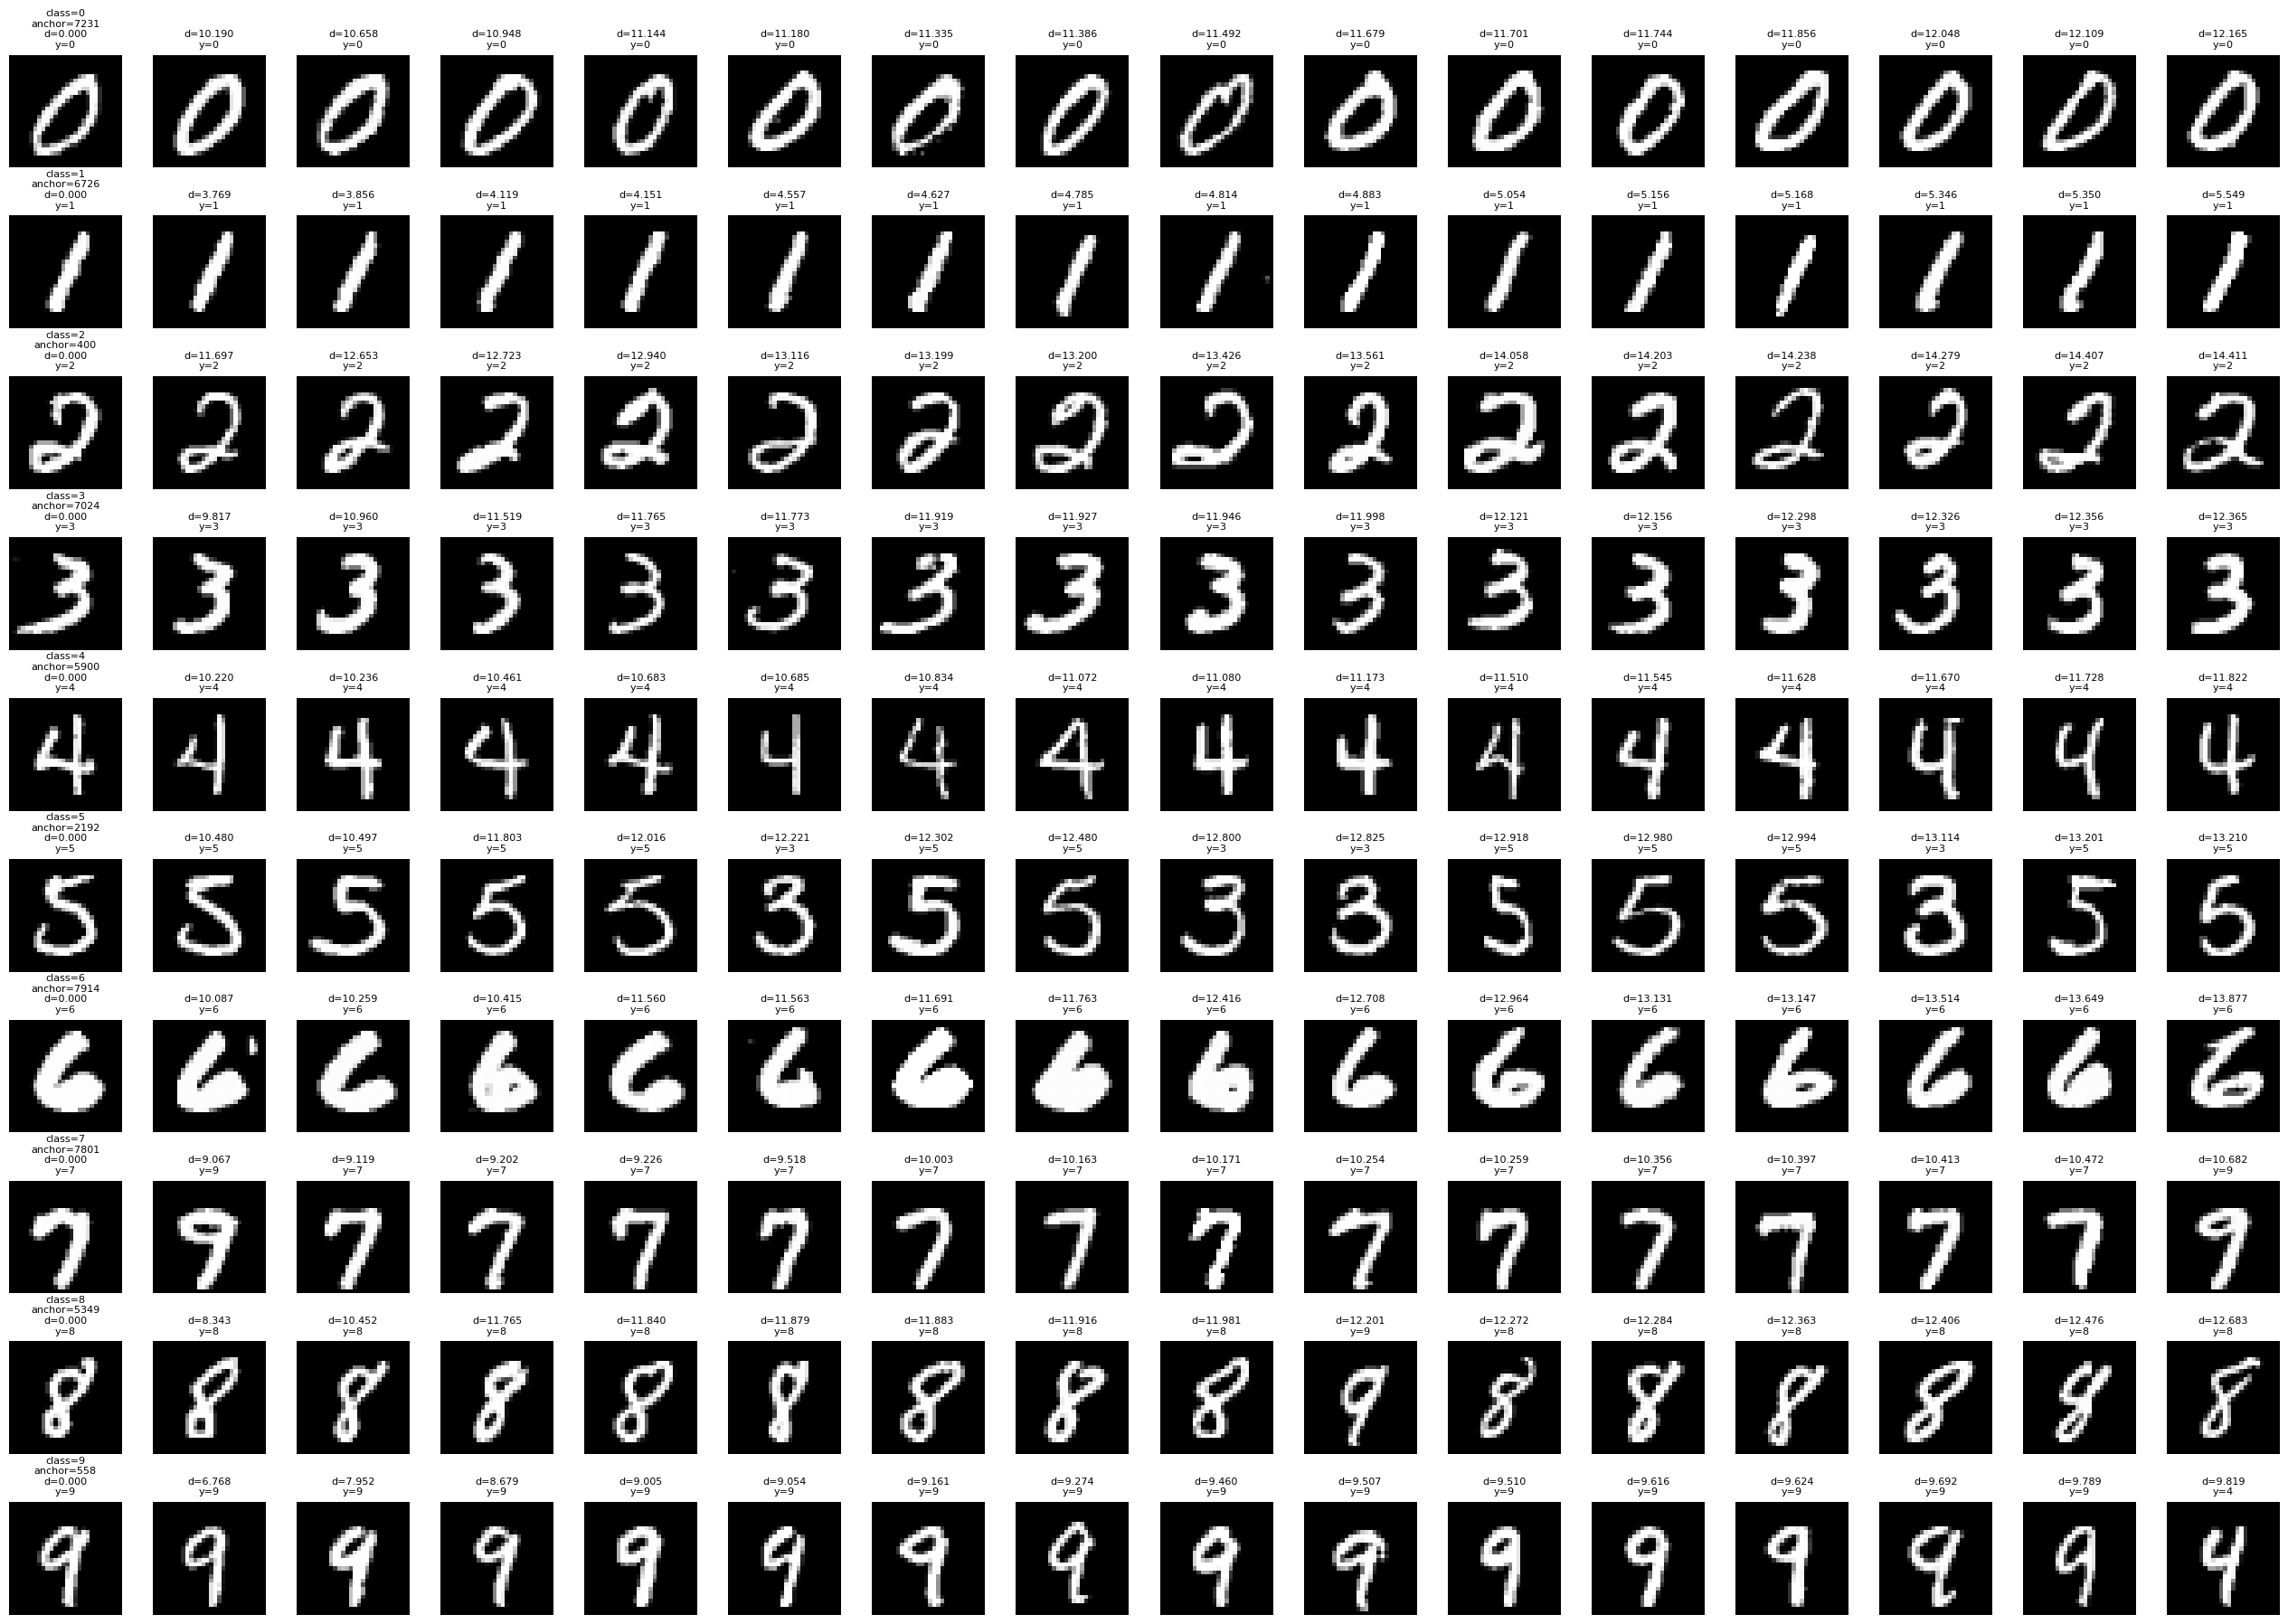

In [19]:
show_class_neighbor_grid(test_images,
                         indices,
                         distances,
                         labels=test_labels,
                         num_neighbors=15,
                         classes=classes)

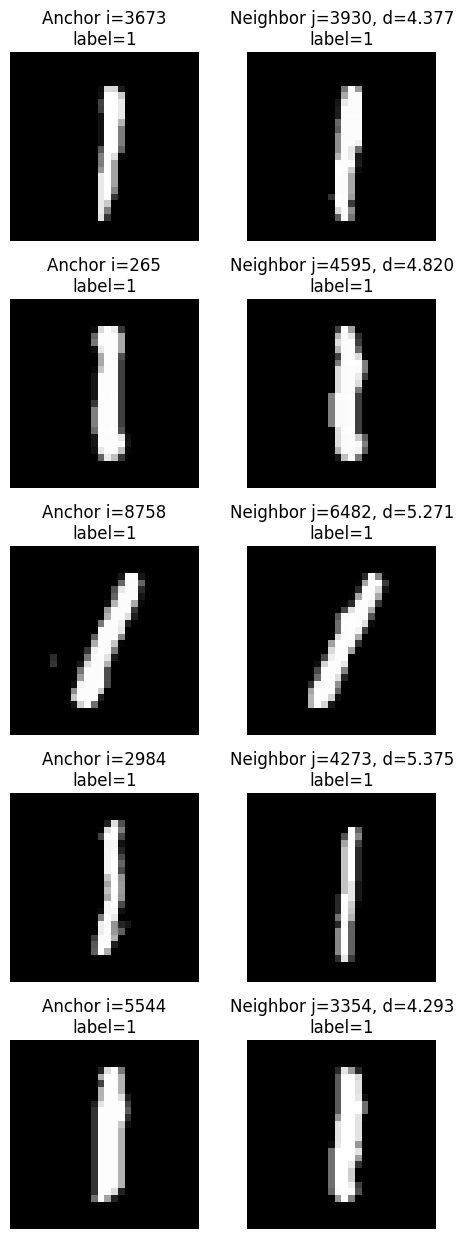

In [20]:
show_neighbor_pairs(test_images, indices, distances, tau_x, num_pairs=5, labels=test_labels)

## Plot Wavelet Decomposition

In [21]:
import pywt

def plot_wavelet_decomposition(img, wavelet="haar"):
    """
    Plot a grayscale MNIST image + its single-level wavelet decomposition.

    img: (1, 28, 28) or (28, 28), values in [0, 1]
    """
    if hasattr(img, "numpy"):
        img = img.numpy()
    img = np.squeeze(img)

    LL, (LH, HL, HH) = pywt.dwt2(img, wavelet)

    fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
    for ax, (arr, title) in zip(axes, [(img, "Original"), (LL, "LL"),
                                       (LH, "LH"), (HL, "HL"), (HH, "HH")]):
        ax.imshow(arr, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

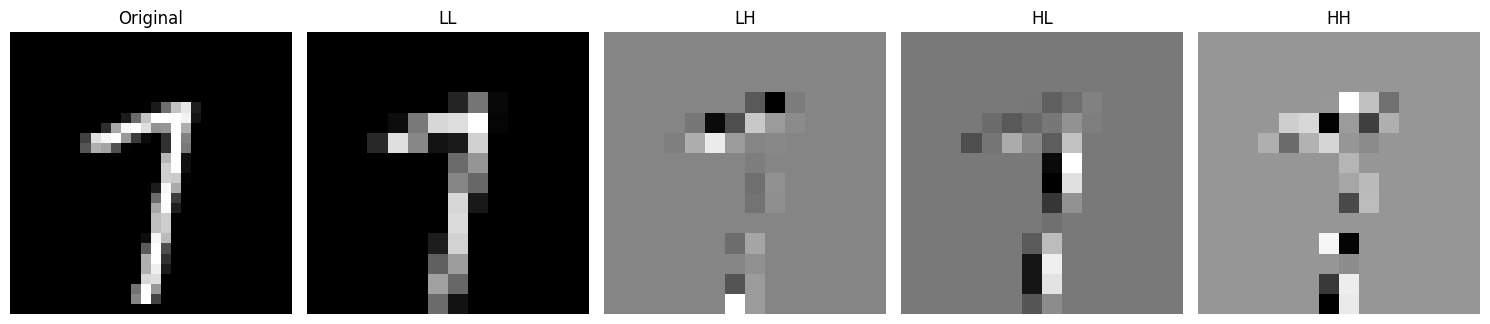

In [22]:
plot_wavelet_decomposition(unnormalize(train_images[42]))

# Average Kernel Size for Random Labels

In [23]:
def add_label_noise(labels, frac, num_classes=10, seed=42):
    rng = np.random.default_rng(seed)
    y = np.array(labels)
    idx = rng.choice(len(y), int(frac * len(y)), replace=False)
    y[idx] = (y[idx] + rng.integers(1, num_classes, len(idx))) % num_classes
    return y, idx

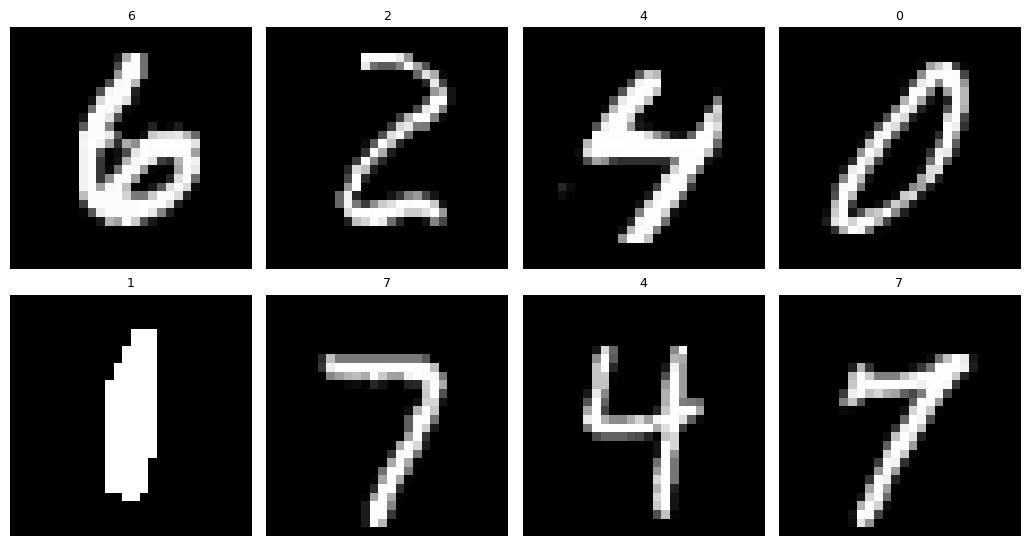

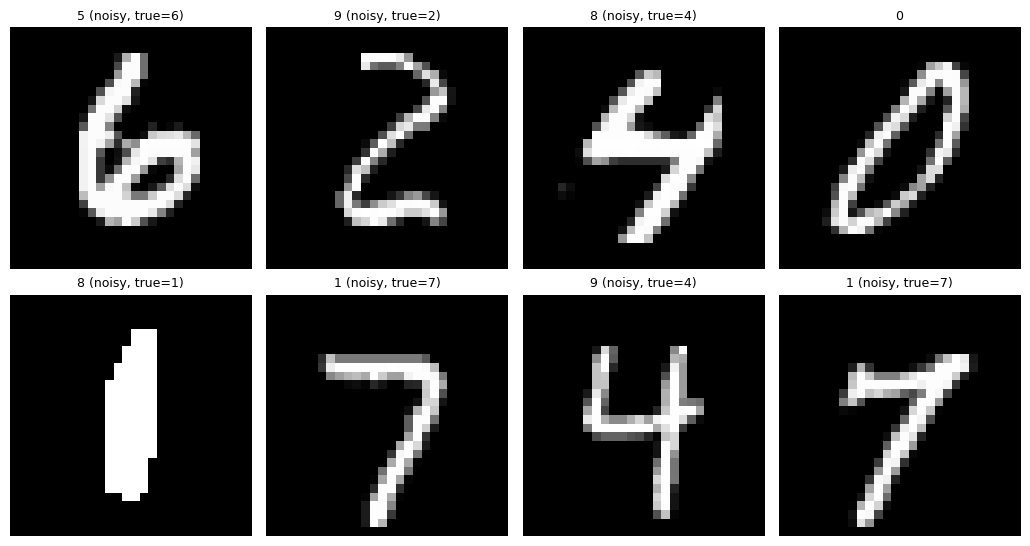

In [24]:
noise_seed = 42

def show_examples(images, labels, clean_labels, n=8, ncols=4, seed=0):
    idx = np.random.default_rng(seed).choice(len(images), n, replace=False)
    fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, figsize=(2.6 * ncols, 2.8 * n / ncols), squeeze=False)
    for ax, i in zip(axes.flat, idx):
        ax.imshow(unnormalize(images[i])[0], cmap="gray")
        y, y_clean = labels[i], clean_labels[i]
        ax.set_title(f"{y}" if y == y_clean else f"{y} (noisy, true={y_clean})", fontsize=9)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


noisy_labels_09, _ = add_label_noise(train_labels, 0.9, seed=noise_seed)
show_examples(train_images, train_labels, train_labels)
show_examples(train_images, noisy_labels_09, train_labels)

In [25]:
noise_seed = 42

train_result_dict_noisy = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.05, 0.06, 0.07, 0.08, 0.08, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
noise_list = [0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None  # go through N_max in reverse order to only compute the largest N once

for N_id, N_max in enumerate(N_list):
    train_result_dict_noisy[N_max] = {}

    for noise_id, noise_level in enumerate(noise_list):
        train_result_dict_noisy[N_max][noise_level] = {}

        noisy_labels, _ = add_label_noise(train_labels, noise_level, seed=noise_seed)

        for qx_id, qx in enumerate(qx_list):
            train_result_dict_noisy[N_max][noise_level][qx] = {"avg_ker_size": None,
                                                               "tau_x": None,
                                                               "N_k_stats": None}

            print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   ",
                  f"Noise [{noise_id+1}/{len(noise_list)}]: {noise_level}   |   ",
                  f"N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")

            feas = feasible_sets_classification_nn(train_features, noisy_labels,
                                                   N_max=N_max,
                                                   qx=qx,
                                                   neighbor_stats=neighbor_stats)

            tau_x = feas["tau_x"]
            feasible_sets = feas["feasible_sets"]
            D_prime = feas["D_prime"]

            if neighbor_stats is None:
                neighbor_stats = {"distances": feas["distances"],
                                  "indices": feas["indices"]}

            average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
            train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"] = average_kersize
            train_result_dict_noisy[N_max][noise_level][qx]["tau_x"] = tau_x
            train_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"] = Nk_stats

In [26]:
### Noise Eval
N_max = 200
qx = 0.1
noise_level = 0.2
print("average_kersize on train set: ", train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Lower accuracy bound:", 1 - train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Upper accuracy bound:", 1 - 0.5 * train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("tau_x:", train_result_dict_noisy[N_max][noise_level][qx]["tau_x"])
print("Nk:", train_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"])

average_kersize on train set:  0.27854521279234584
Lower accuracy bound: 0.7214547872076542
Upper accuracy bound: 0.8607273936038271
tau_x: 4.732302331924439
Nk: (1, 4.463, 1.0, 186)


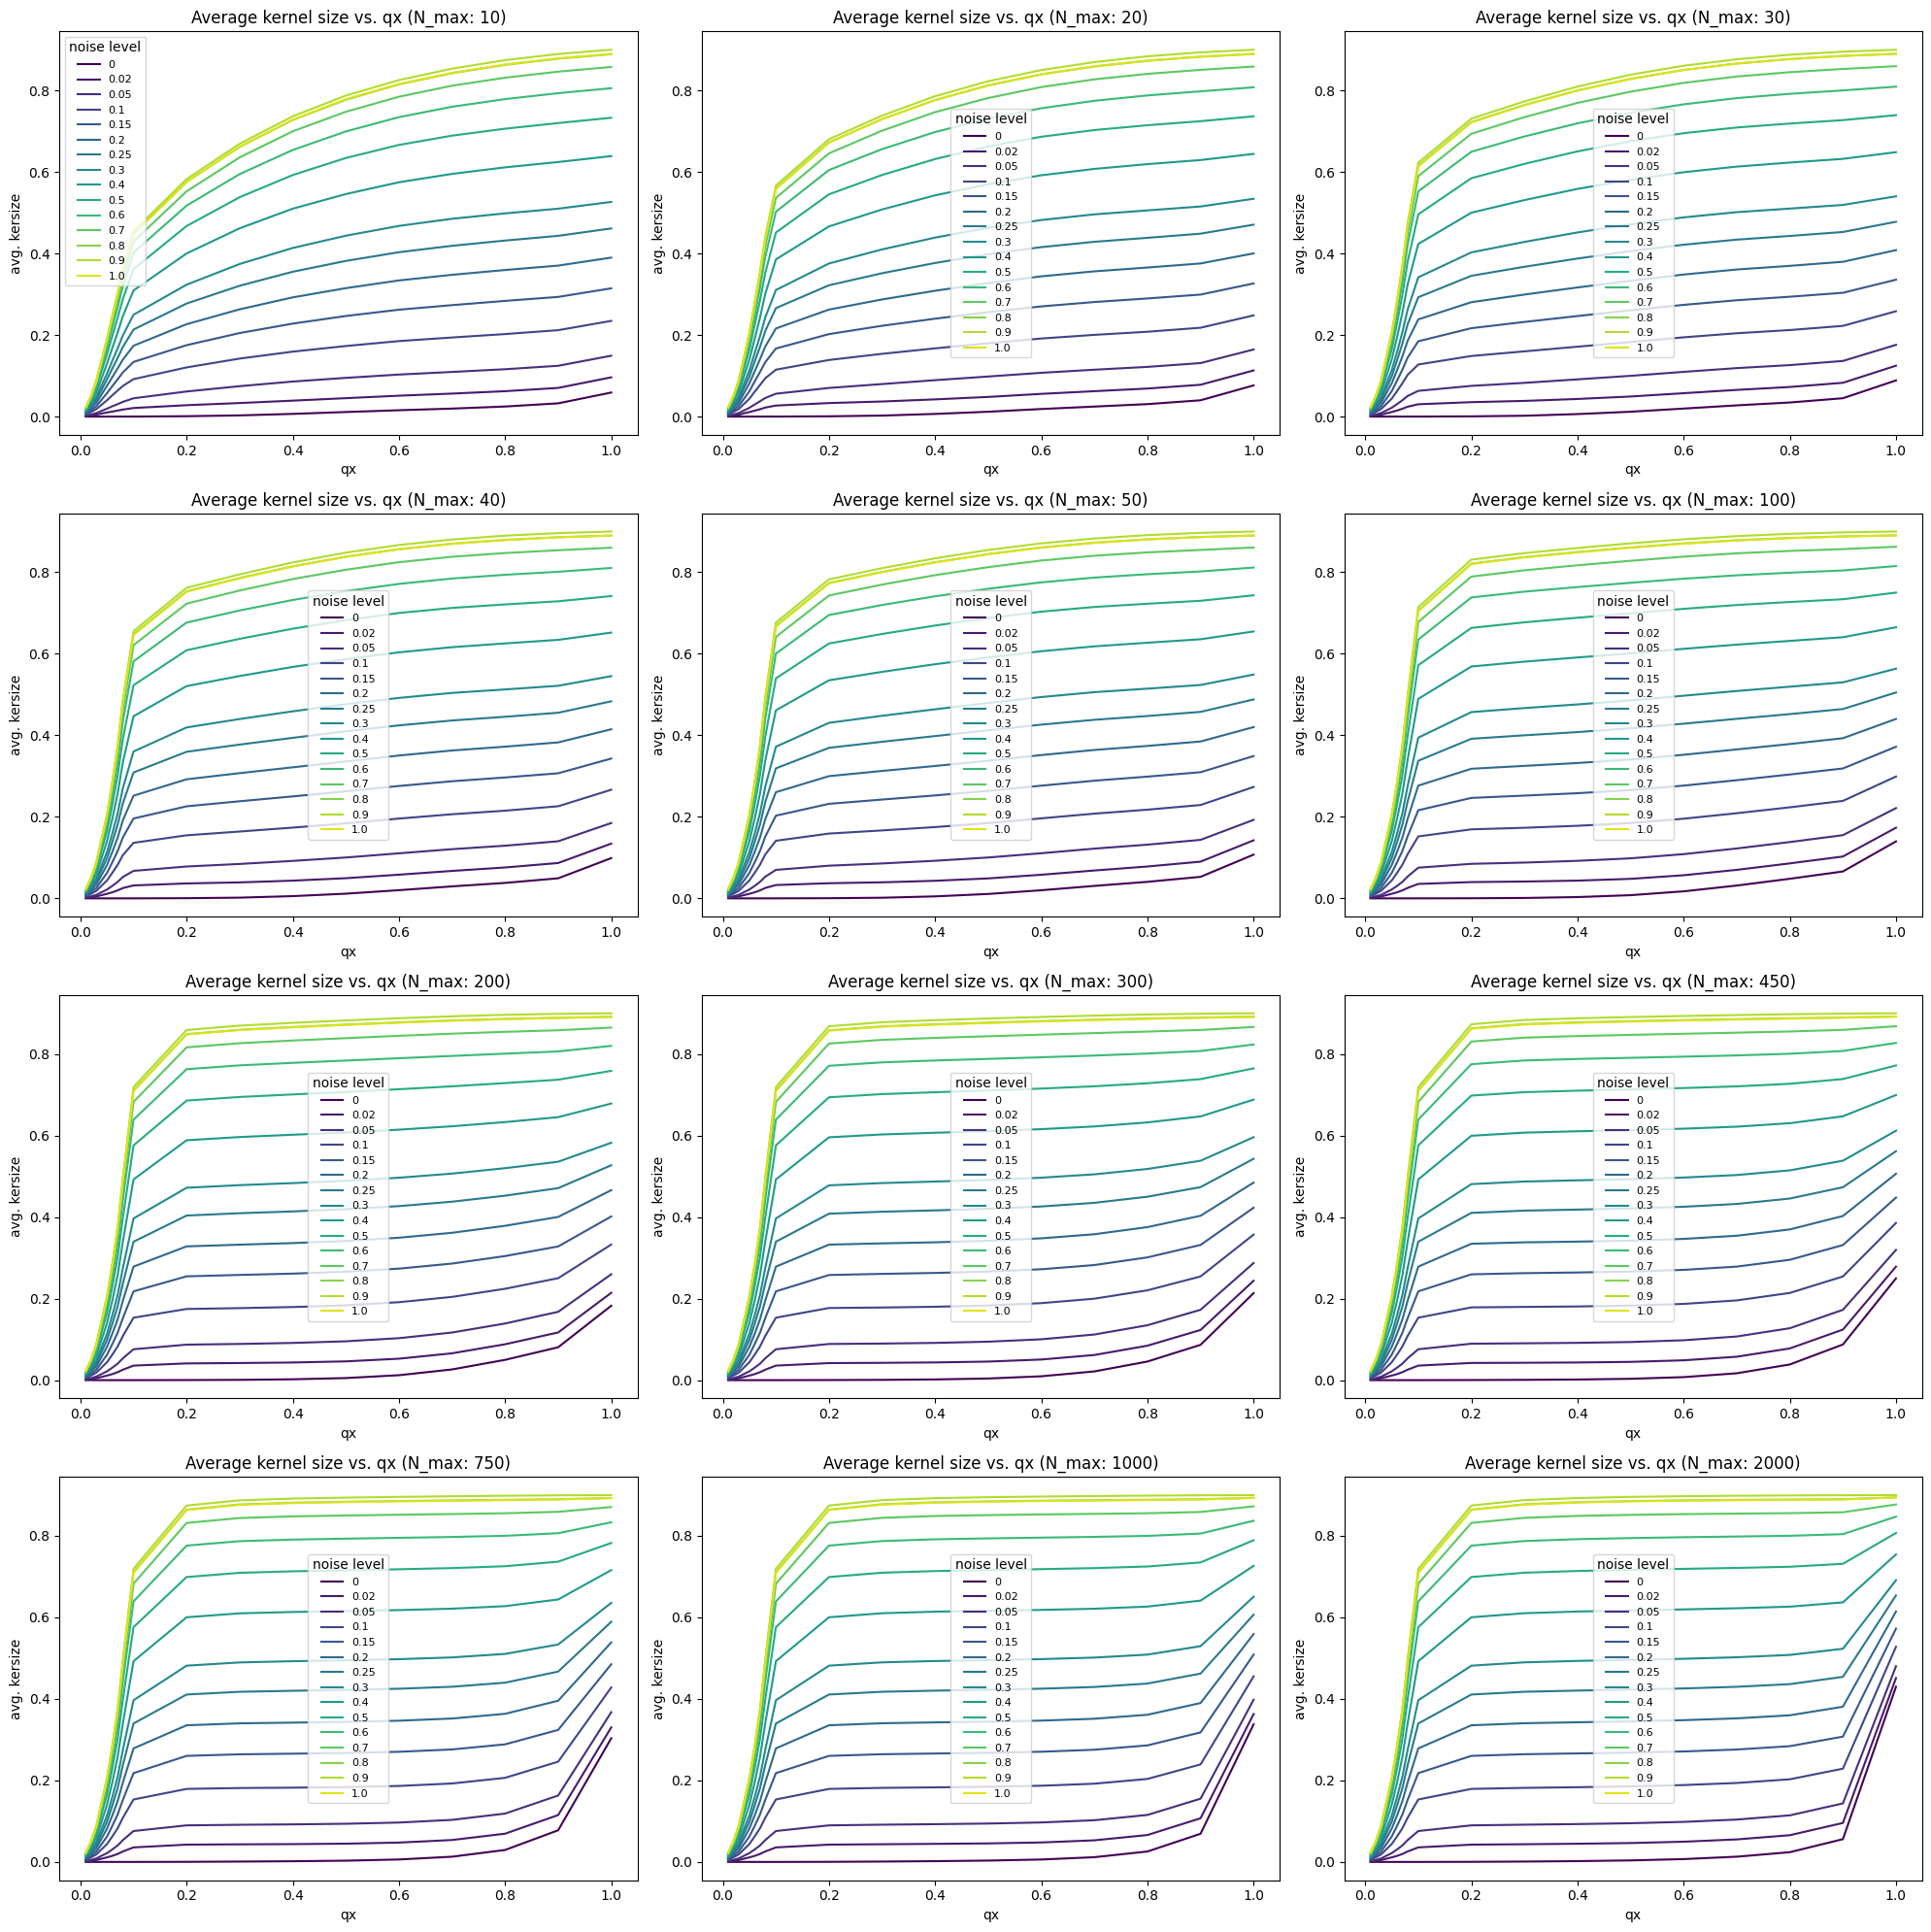

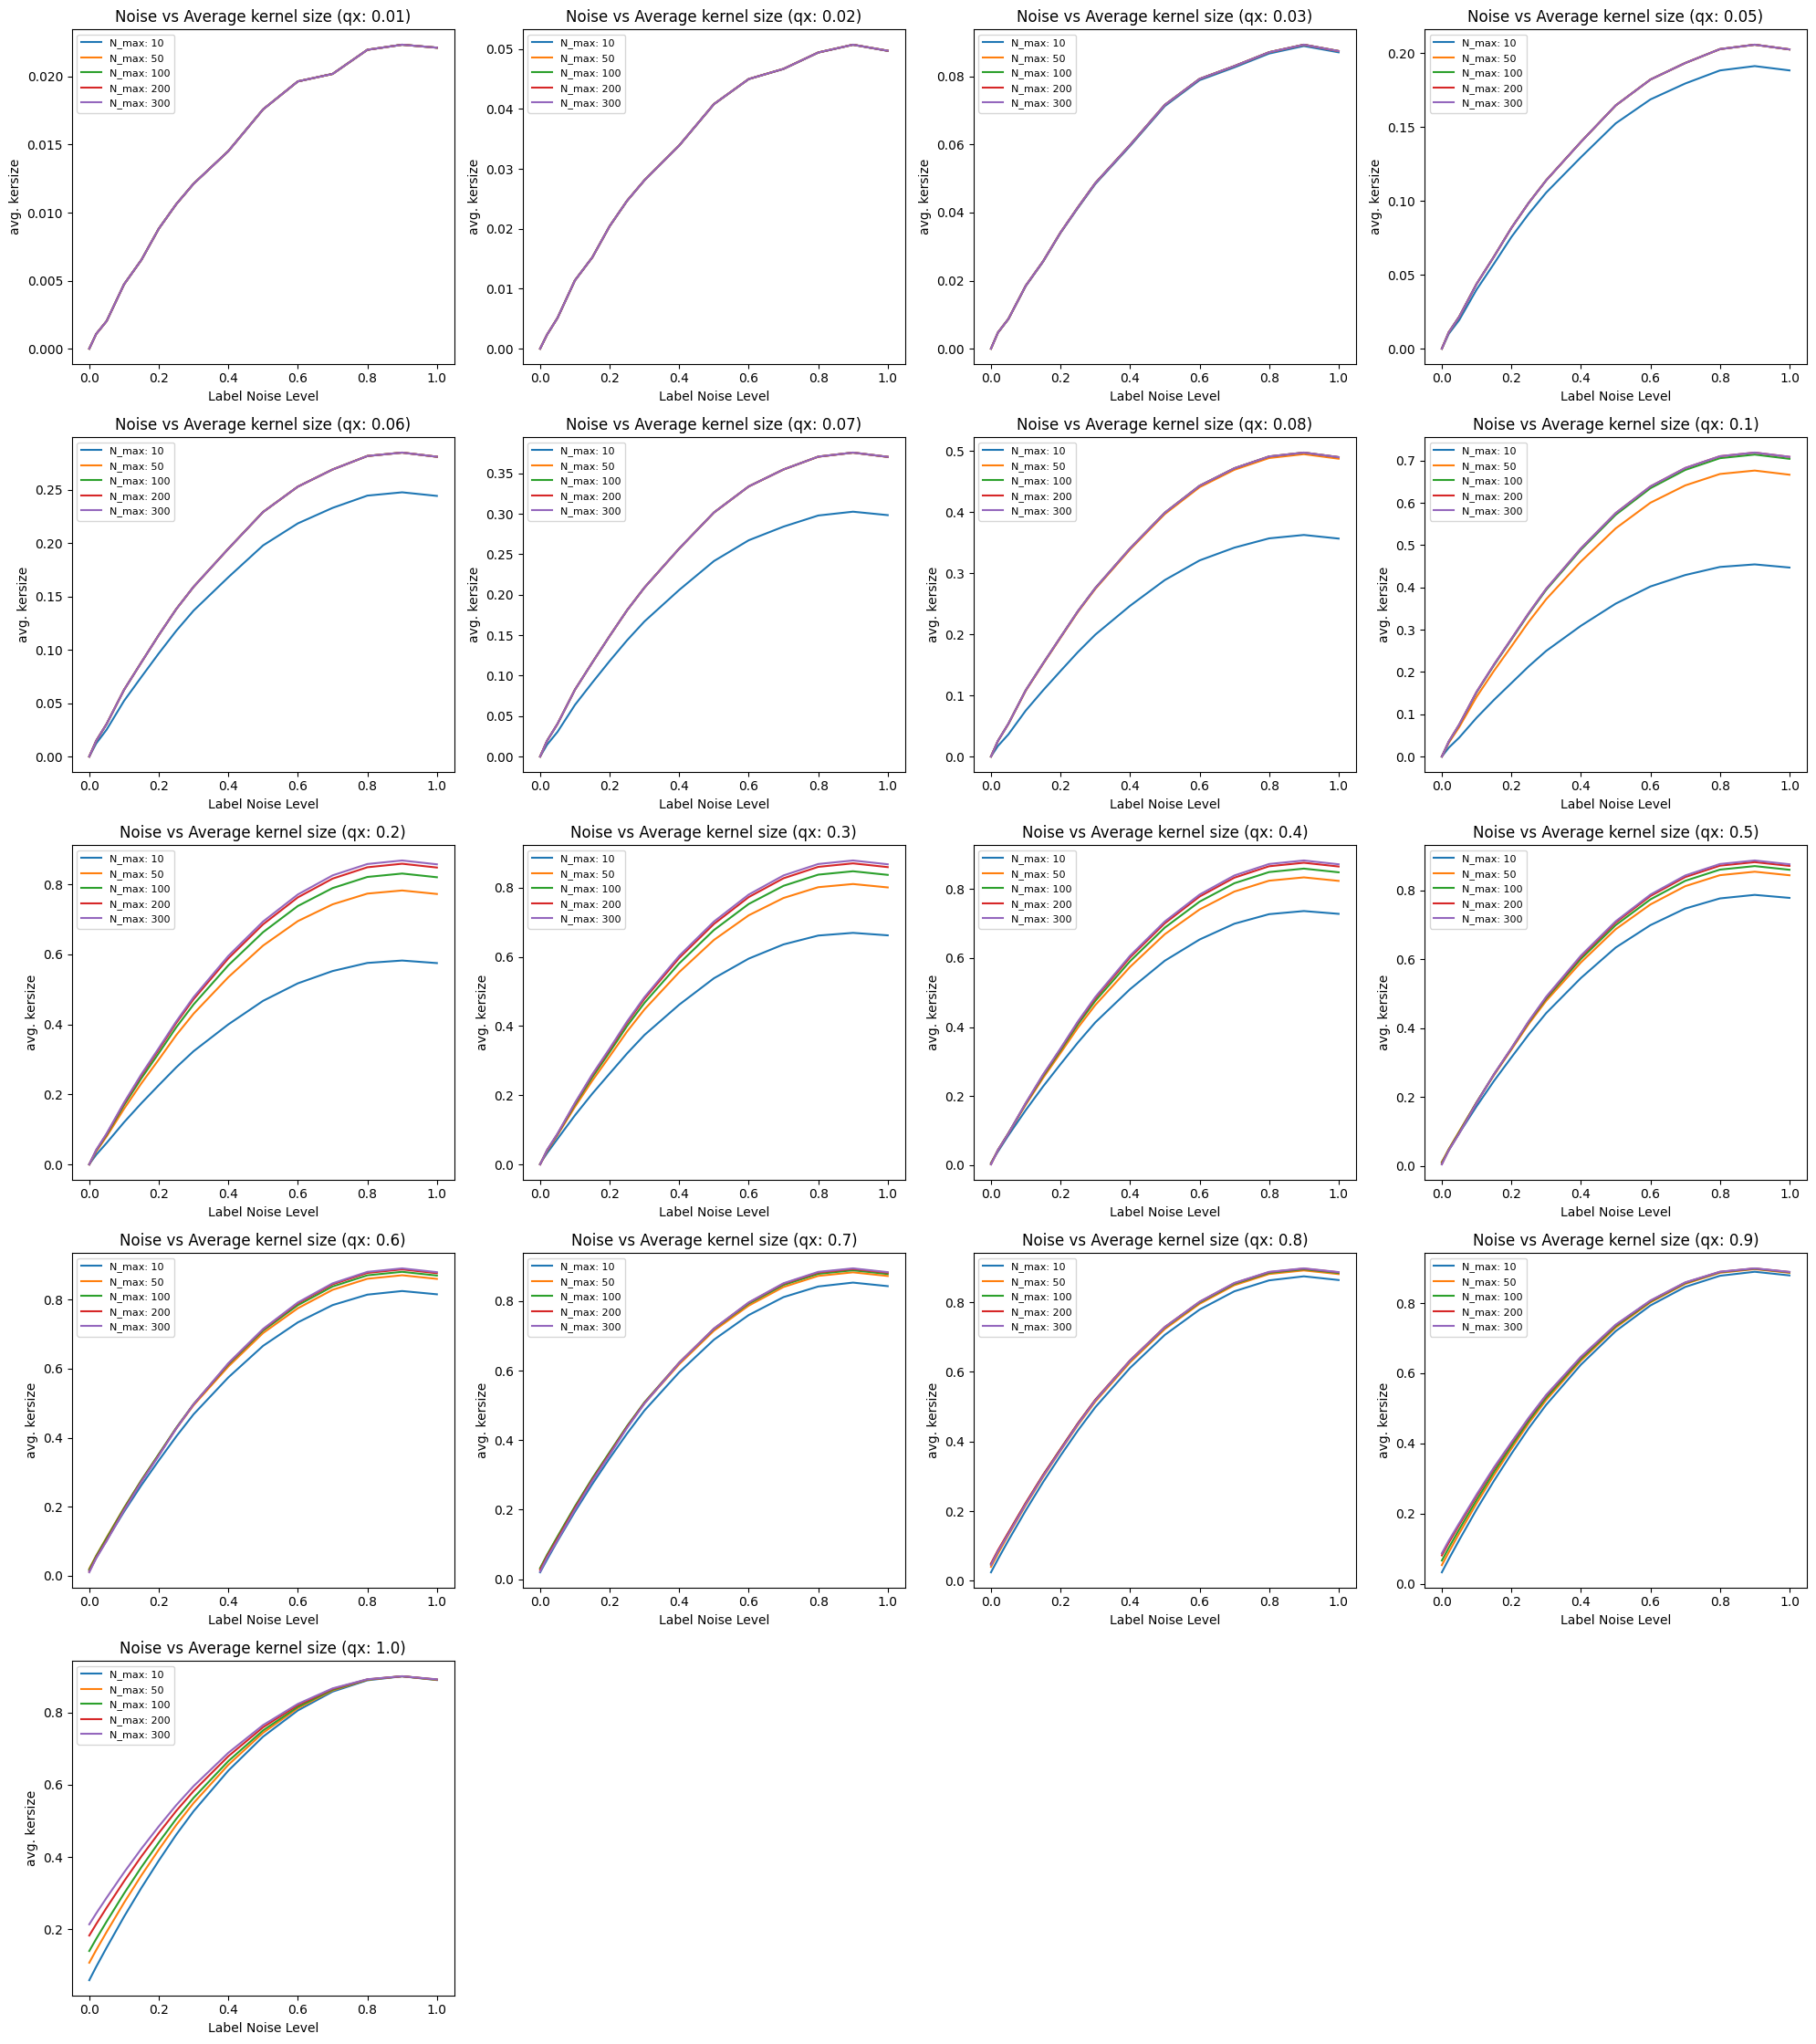

In [27]:
res = train_result_dict_noisy
n_max_list = sorted(res)
noise_levels = list(res[n_max_list[0]])
qx_values = list(res[n_max_list[0]][noise_levels[0]])
colors = plt.cm.viridis(np.linspace(0, 0.95, len(noise_levels)))

# --- average kernel size vs. qx: one panel per N_max, one line per noise level ---
num_cols = 3
fig, ax = plt.subplots(int(np.ceil(len(n_max_list) / num_cols)), num_cols,
                       figsize=(20, 5 * int(np.ceil(len(n_max_list) / num_cols))), squeeze=False)
for a, n in zip(ax.flat, n_max_list):
    for noise, c in zip(noise_levels, colors):
        a.plot(qx_values, [res[n][noise][qx]["avg_ker_size"] for qx in qx_values], color=c, label=noise)
    a.set_title(f"Average kernel size vs. qx (N_max: {n})")
    a.set_xlabel("qx")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8, title="noise level")
for a in ax.flat[len(n_max_list):]:
    a.axis("off")
plt.tight_layout()
plt.show()

# --- average kernel size vs. noise level: one panel per qx, one line per N_max ---
n_value_list = [10, 50, 100, 200, 300]
num_cols = 4
fig, ax = plt.subplots(int(np.ceil(len(qx_values) / num_cols)), num_cols,
                       figsize=(20, 4.5 * int(np.ceil(len(qx_values) / num_cols))), squeeze=False)
for a, qx in zip(ax.flat, qx_values):
    for n in n_value_list:
        a.plot(noise_levels, [res[n][noise][qx]["avg_ker_size"] for noise in noise_levels], label=f"N_max: {n}")
    a.set_title(f"Noise vs Average kernel size (qx: {qx})")
    a.set_xlabel("Label Noise Level")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8)
for a in ax.flat[len(qx_values):]:
    a.axis("off")
plt.tight_layout()
plt.show()

In [28]:
noise_seed = 42

test_result_dict_noisy = {}

N_list = sorted([10, 20, 30, 40, 50, 100, 200, 300, 450, 750, 1000, 2000], reverse=True)
qx_list = [0.01, 0.02, 0.03, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
noise_list = [0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

neighbor_stats = None # go though N_max in reverse order to only compute the larges N once

for N_id, N_max in enumerate(N_list):
    test_result_dict_noisy[N_max] ={}

    for noise_id, noise_level in enumerate(noise_list):
        test_result_dict_noisy[N_max][noise_level] = {}

        noisy_labels, _ = add_label_noise(test_labels, noise_level, seed=noise_seed)

        for qx_id, qx in enumerate(qx_list): 
            test_result_dict_noisy[N_max][noise_level][qx] = {"avg_ker_size": None, 
                                                               "tau_x": None,
                                                               "N_k_stats": None}


            print(f"qx [{qx_id+1}/{len(qx_list)}]: {qx}   |   ",\
                  f"Noise [{noise_id+1}/{len(noise_list)}]: {noise_level}   |   ",\
                  f"N_max [{N_id+1}/{len(N_list)}]: {N_max} ...           ", end="\r")
            
            feas = feasible_sets_classification_nn(test_features, noisy_labels, 
                                                N_max=N_max,
                                                qx=qx,
                                                neighbor_stats=neighbor_stats)
            
            tau_x= feas["tau_x"]
            feasible_sets= feas["feasible_sets"]
            D_prime = feas["D_prime"]

            if neighbor_stats is None: 
                neighbor_stats = {"distances": feas["distances"],
                                "indices": feas["indices"]}

            average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
            test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"] = average_kersize
            test_result_dict_noisy[N_max][noise_level][qx]["tau_x"] = tau_x
            test_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"] = Nk_stats

In [29]:
### Noise Eval
N_max = 200
qx = 0.1
noise_level = 0.2
print("average_kersize on test set: ", test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Lower accuracy bound:", 1 - test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("Upper accuracy bound:", 1 - 0.5 * test_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"])
print("tau_x:", test_result_dict_noisy[N_max][noise_level][qx]["tau_x"])
print("Nk:", test_result_dict_noisy[N_max][noise_level][qx]["N_k_stats"])

average_kersize on test set:  0.2549481978901043
Lower accuracy bound: 0.7450518021098957
Upper accuracy bound: 0.8725259010549479
tau_x: 5.381924390792848
Nk: (1, 2.51, 1.0, 71)


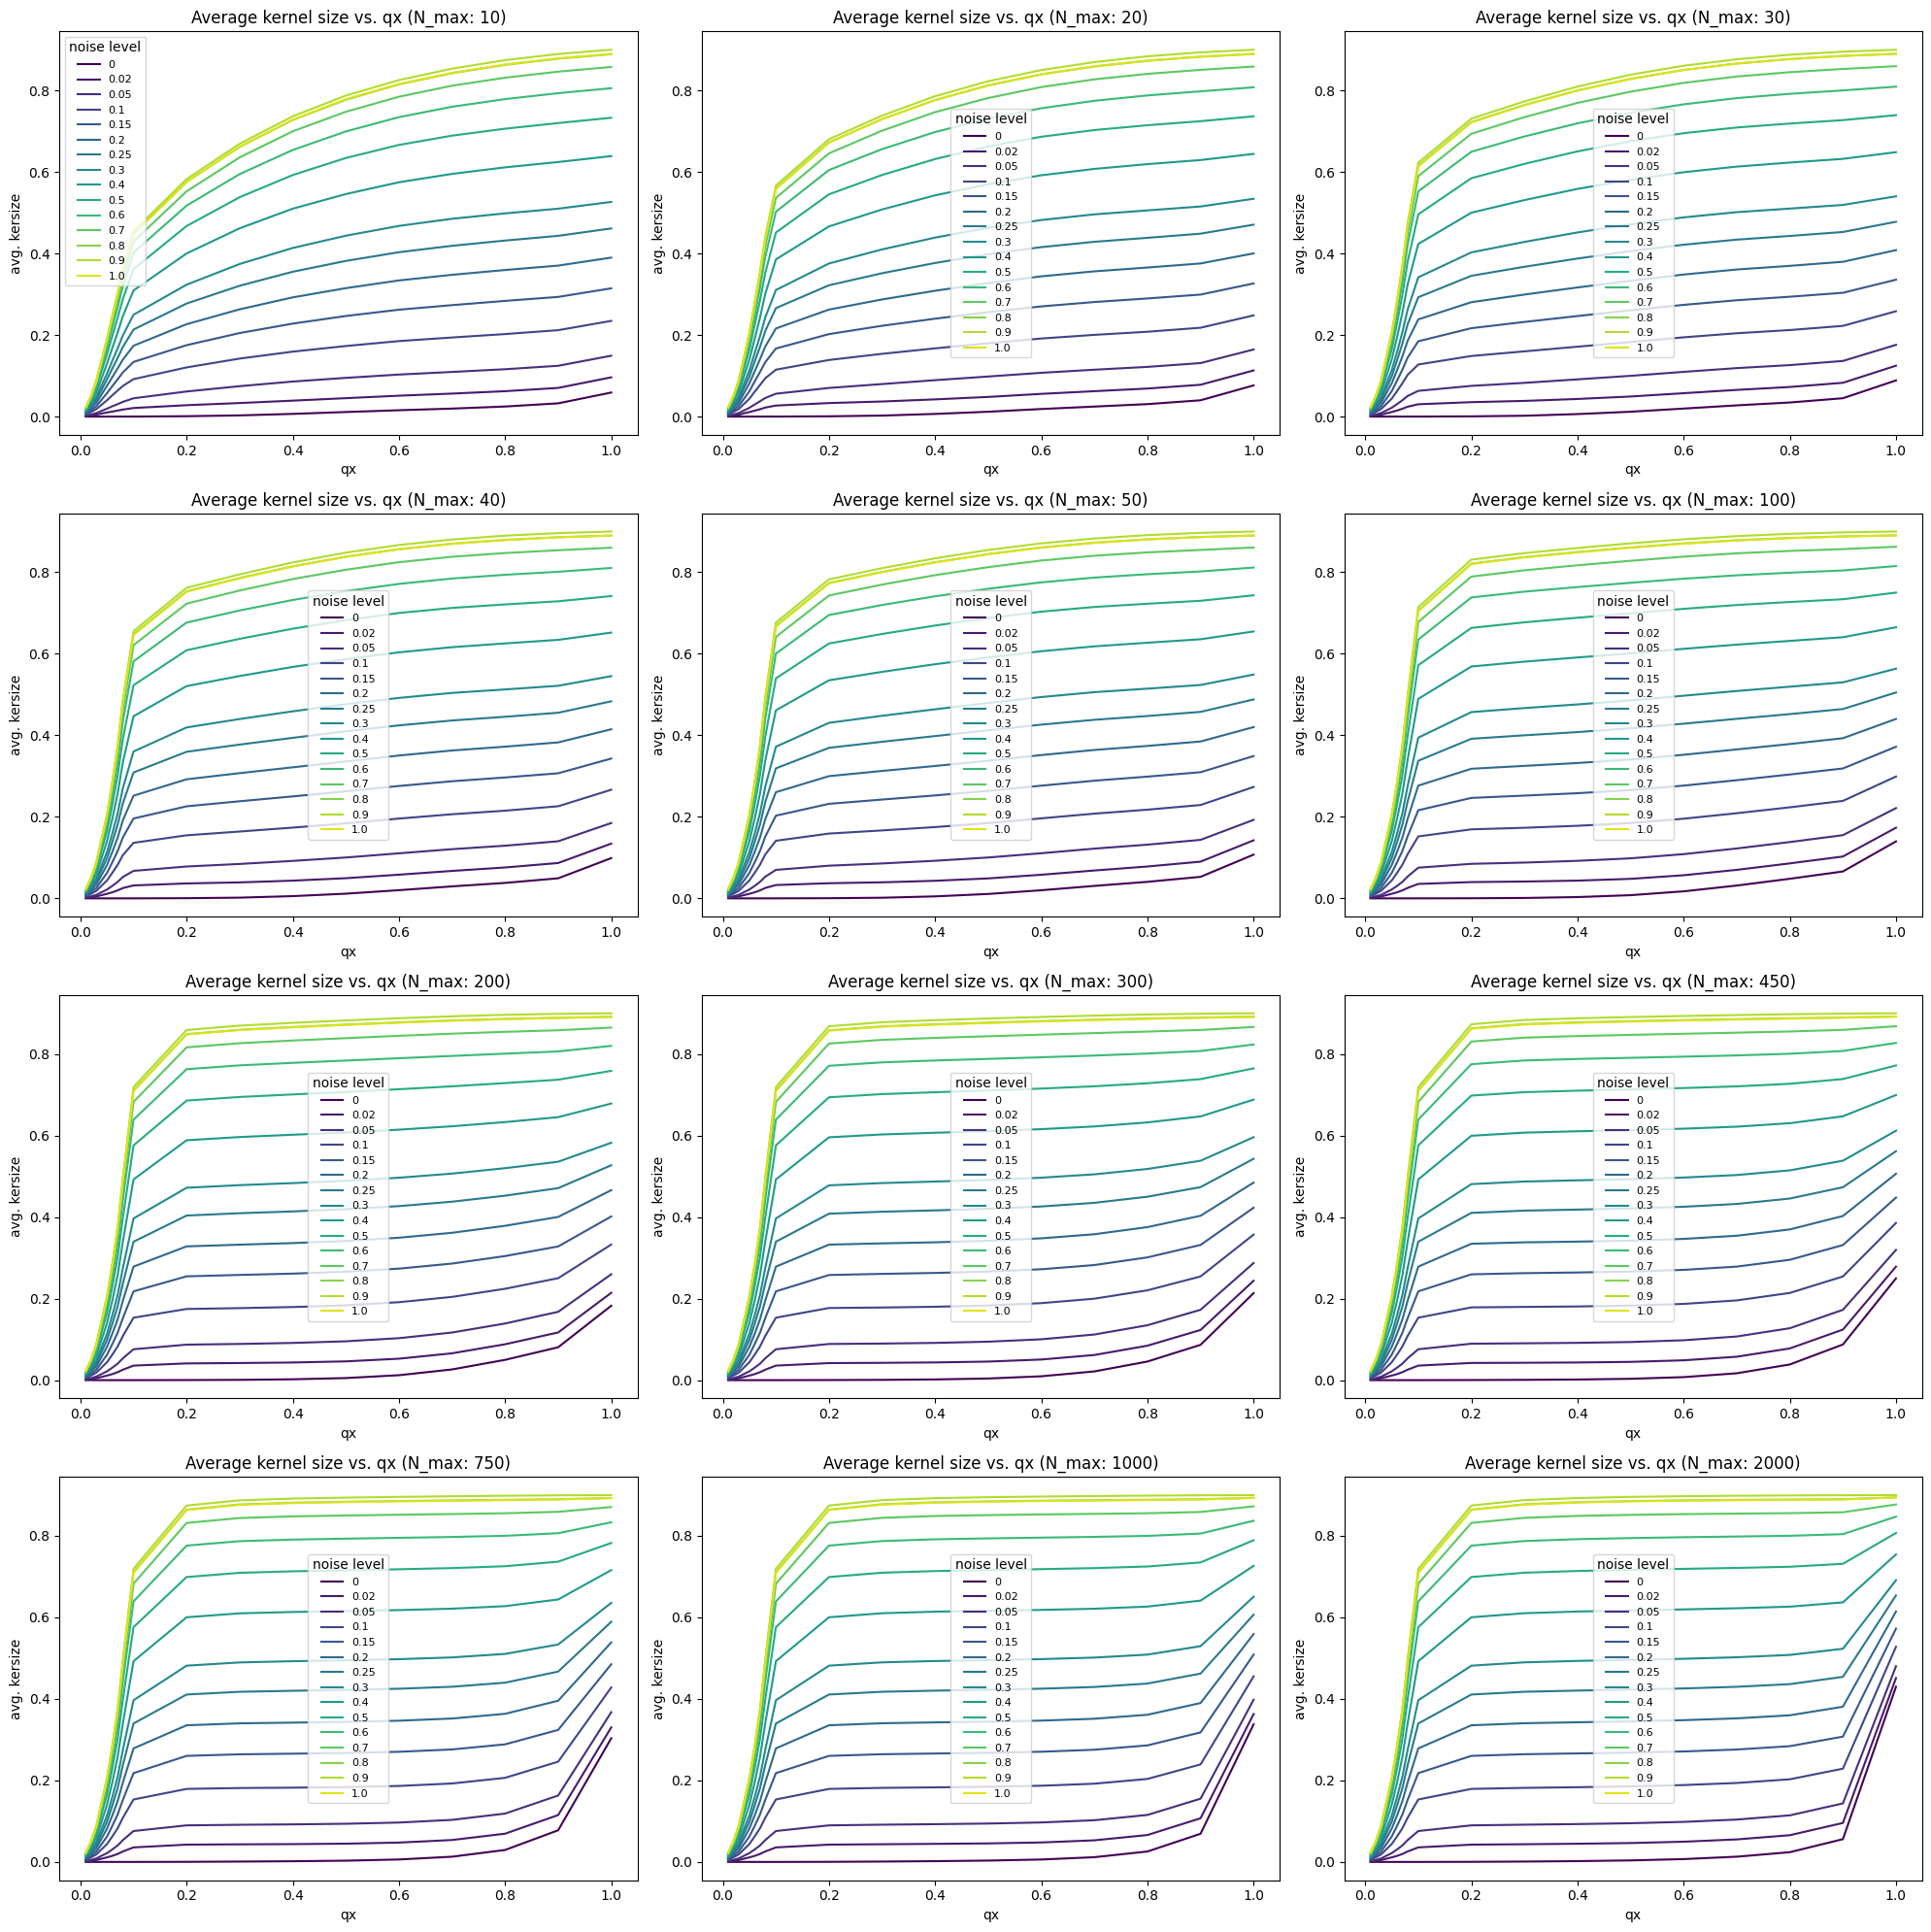

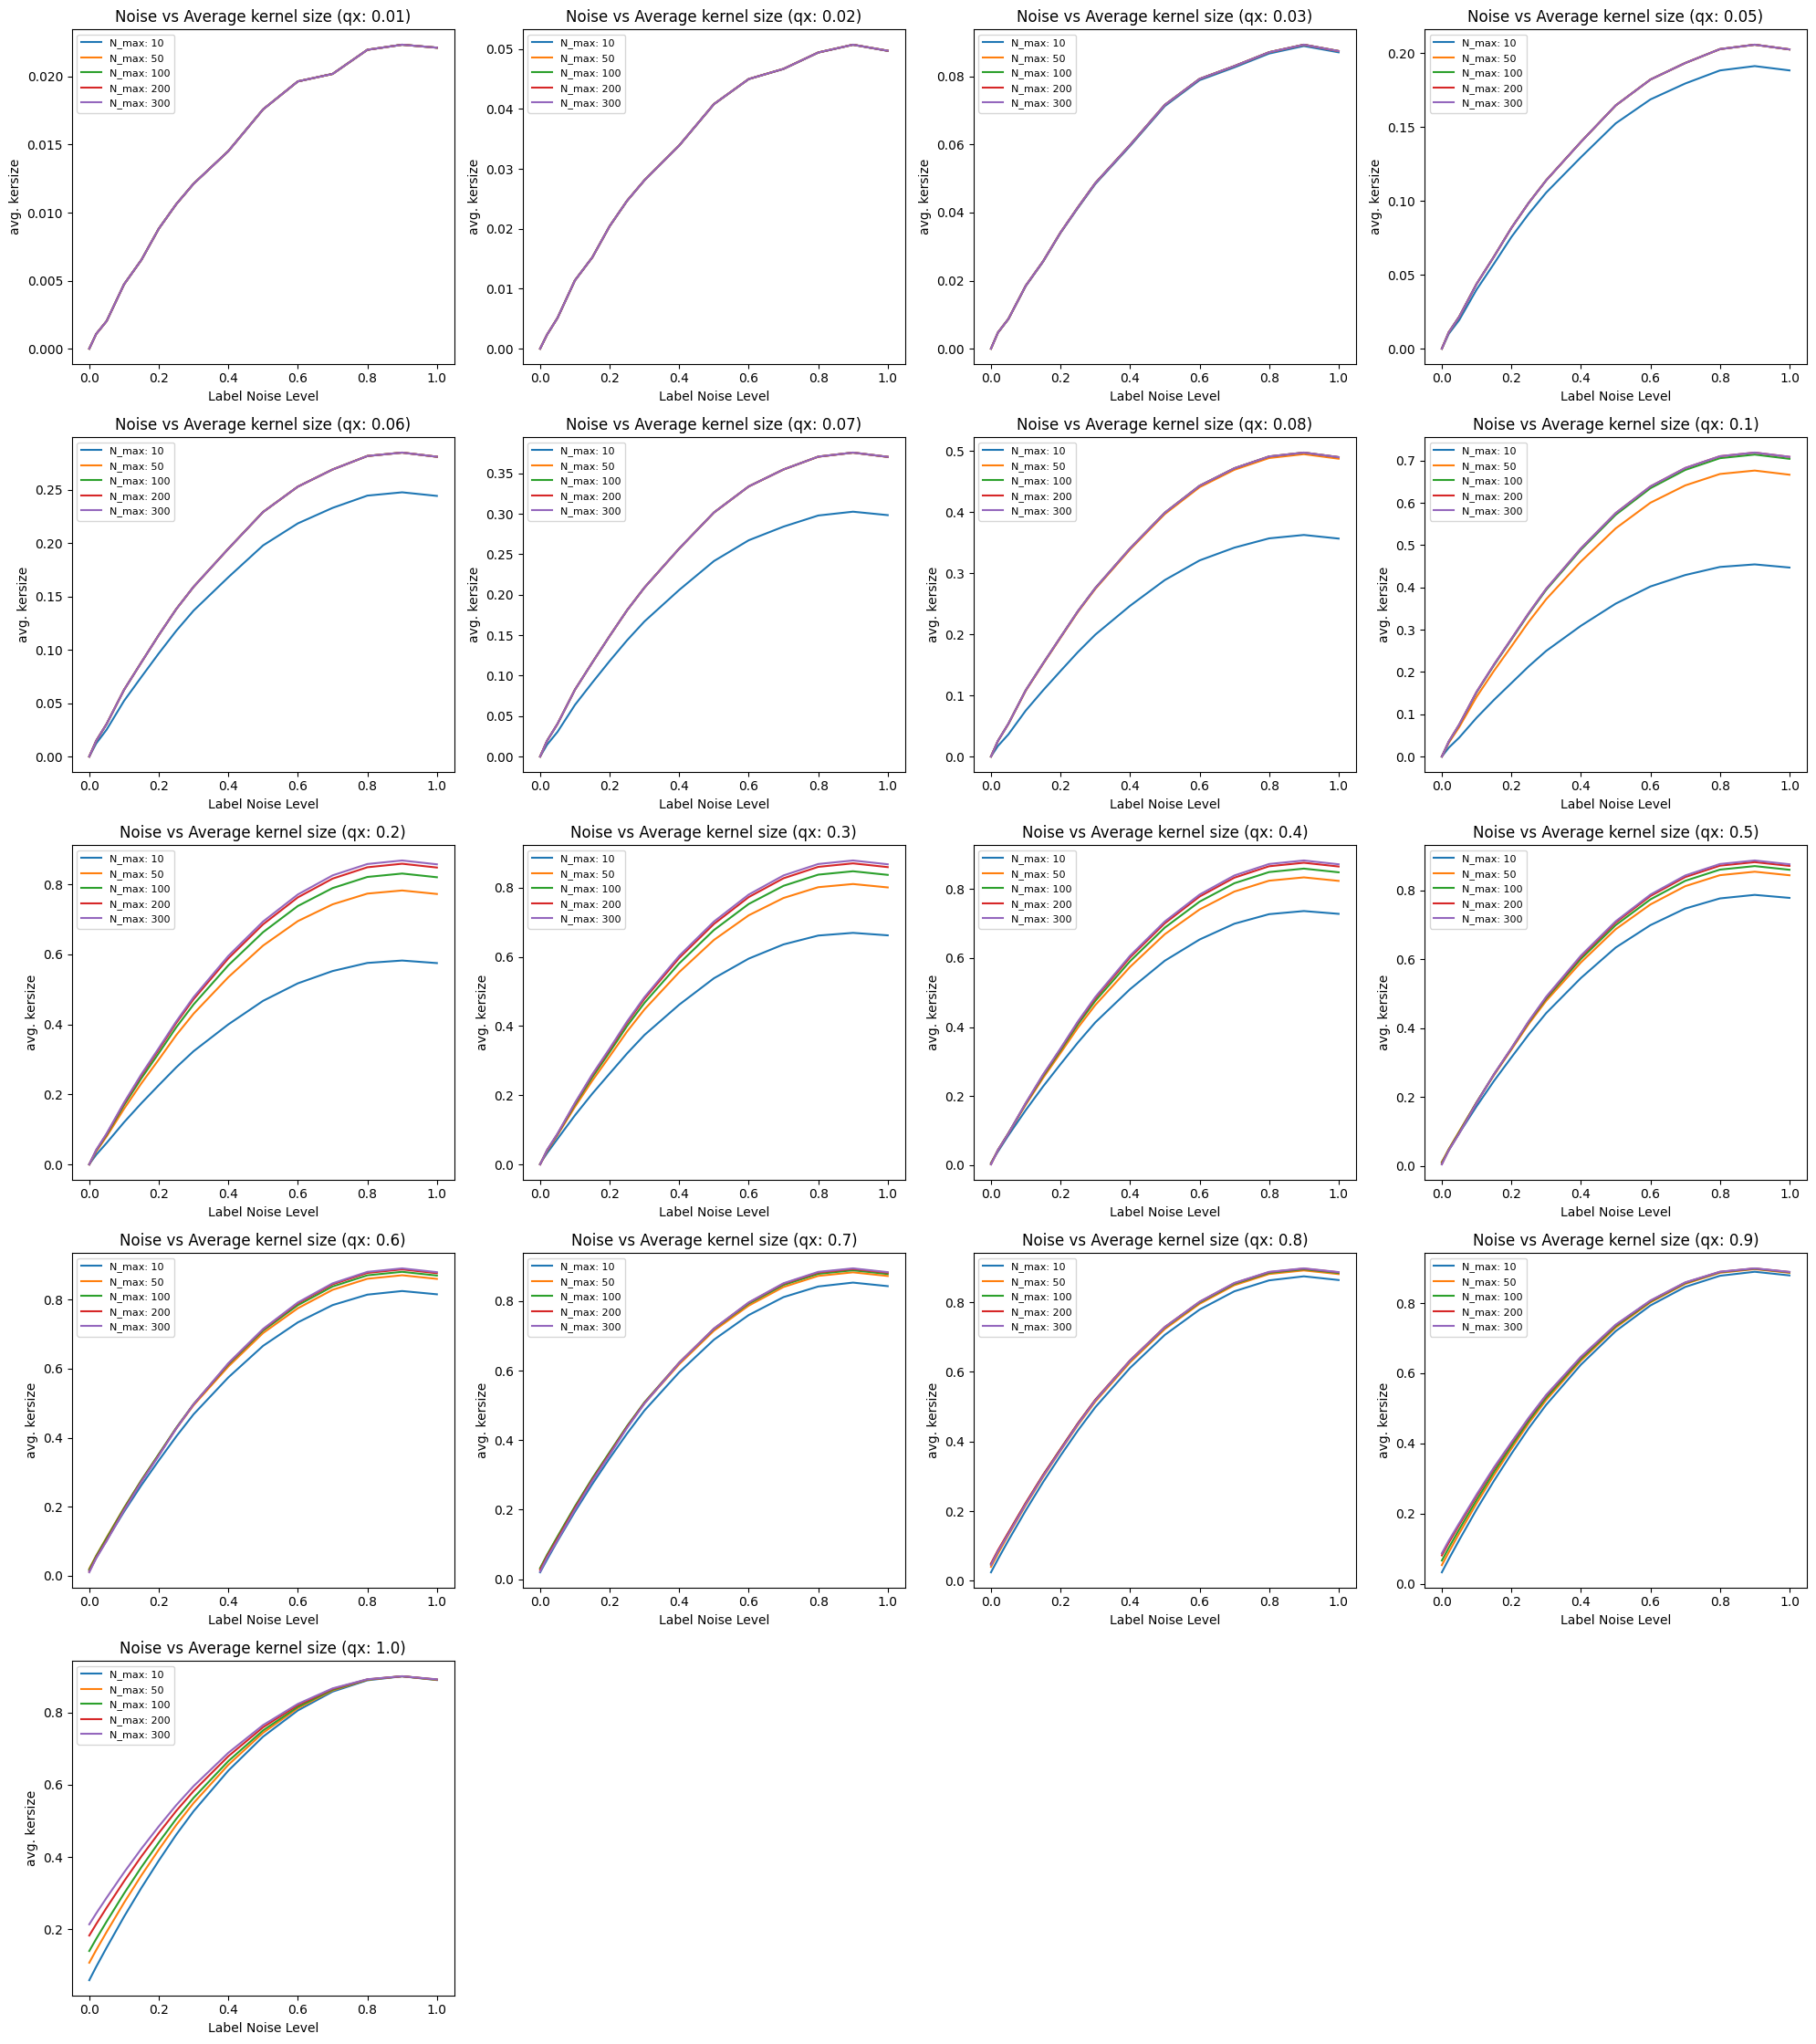

In [30]:
# train_result_dict_noisy[N_max][noise_level][qx]["avg_ker_size"]
res = train_result_dict_noisy
n_max_list = sorted(res)
noise_levels = list(res[n_max_list[0]])
qx_values = list(res[n_max_list[0]][noise_levels[0]])
colors = plt.cm.viridis(np.linspace(0, 0.95, len(noise_levels)))

# --- average kernel size vs. qx: one panel per N_max, one line per noise level ---
num_cols = 3
fig, ax = plt.subplots(int(np.ceil(len(n_max_list) / num_cols)), num_cols,
                       figsize=(20, 5 * int(np.ceil(len(n_max_list) / num_cols))), squeeze=False)
for a, n in zip(ax.flat, n_max_list):
    for noise, c in zip(noise_levels, colors):
        a.plot(qx_values, [res[n][noise][qx]["avg_ker_size"] for qx in qx_values], color=c, label=noise)
    a.set_title(f"Average kernel size vs. qx (N_max: {n})")
    a.set_xlabel("qx")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8, title="noise level")
for a in ax.flat[len(n_max_list):]:
    a.axis("off")
plt.tight_layout()
plt.show()

# --- average kernel size vs. noise level: one panel per qx, one line per N_max ---
n_value_list = [10, 50, 100, 200, 300]
num_cols = 4
fig, ax = plt.subplots(int(np.ceil(len(qx_values) / num_cols)), num_cols,
                       figsize=(20, 4.5 * int(np.ceil(len(qx_values) / num_cols))), squeeze=False)
for a, qx in zip(ax.flat, qx_values):
    for n in n_value_list:
        a.plot(noise_levels, [res[n][noise][qx]["avg_ker_size"] for noise in noise_levels], label=f"N_max: {n}")
    a.set_title(f"Noise vs Average kernel size (qx: {qx})")
    a.set_xlabel("Label Noise Level")
    a.set_ylabel("avg. kersize")
    a.legend(fontsize=8)
for a in ax.flat[len(qx_values):]:
    a.axis("off")
plt.tight_layout()
plt.show()